# Лабораторная работа №3. Понижение размерности
**Тема:** Изучение проблемы высокой размерности, методов PCA, t-SNE и UMAP.

**Датасет:** Uber Delivery Tips (реальные данные о доставке).

**Автор:** Плеханова Арина 303 группа

## Цель работы
1. Изучить проблему высокой размерности данных и её влияние на анализ.
2. Освоить методы линейного и нелинейного снижения размерности.
3. Научиться выявлять скрытую структуру данных и интерпретировать результаты.
4. Научиться интерпретировать новые признаки после преобразования пространства.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import mean_squared_error

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("Библиотеки загружены")

Библиотеки загружены


In [16]:
df = pd.read_csv('uber_delivery_tips_dataset.csv')
print("Размер датасета (строки, столбцы):", df.shape)
df.head()

Размер датасета (строки, столбцы): (1214, 25)


,date,time,fare,tip,earnings,distance,duration,restaurant_address,points,deliveries_count,...,weekday_name,is_weekend,is_holiday,duration_min,speed_mph,part_of_day,earnings_per_mile,earnings_per_hour,tip_pct,driver_binary
0,2025-06-08,20.0,12.30,1.00,13.30,5.57,26m 24s,McDonald's (146 S Fairview Ave),12,1,...,Sunday,True,False,26.400000,12.659091,Evening,2.387792,30.227273,0.075188,0
1,2025-03-08,0.0,5.93,2.00,7.93,2.59,23 min 36 s,"McDonald's, Cliff Dr",2,1,...,Saturday,True,False,23.600000,6.584746,Night,3.061776,20.161017,0.252207,1
2,2025-06-09,11.0,2.64,3.84,6.48,2.30,25m 18s,Su’s Bowl (Isla Vista),3,1,...,Monday,False,False,25.300000,5.454545,Lunch,2.817391,15.367589,0.592593,0
3,2025-06-09,11.5,5.00,0.00,5.00,5.84,40m 50s,Kaiju Ramen and Curry (Isla Vista),6,2,...,Monday,False,False,40.833333,8.581224,Lunch,0.856164,7.346939,0.000000,0
4,2025-03-09,1.0,2.65,6.44,9.09,1.59,12 min 05 s,"Taco Bell, 821 N Milpas St",1,1,...,Sunday,True,False,12.083333,7.895172,Night,5.716981,45.136552,0.708471,1


## Задание 1. Геометрия данных в пространстве признаков

Для анализа возьмём только числовые признаки, так как методы снижения размерности (PCA, t-SNE) работают именно с числами.

In [17]:
numeric_df = df.select_dtypes(include=[np.number]).copy()
numeric_df = numeric_df.loc[:, numeric_df.nunique() > 1] # убираем константы

print(f"Число объектов: {numeric_df.shape[0]}")
print(f"Число числовых признаков: {numeric_df.shape[1]}")
print("Список признаков:", numeric_df.columns.tolist())

Число объектов: 1214
Число числовых признаков: 18
Список признаков: ['time', 'fare', 'tip', 'earnings', 'distance', 'points', 'deliveries_count', 'dropoff_latitude', 'dropoff_longitude', 'restaurant_latitude', 'restaurant_longitude', 'weekday', 'duration_min', 'speed_mph', 'earnings_per_mile', 'earnings_per_hour', 'tip_pct', 'driver_binary']


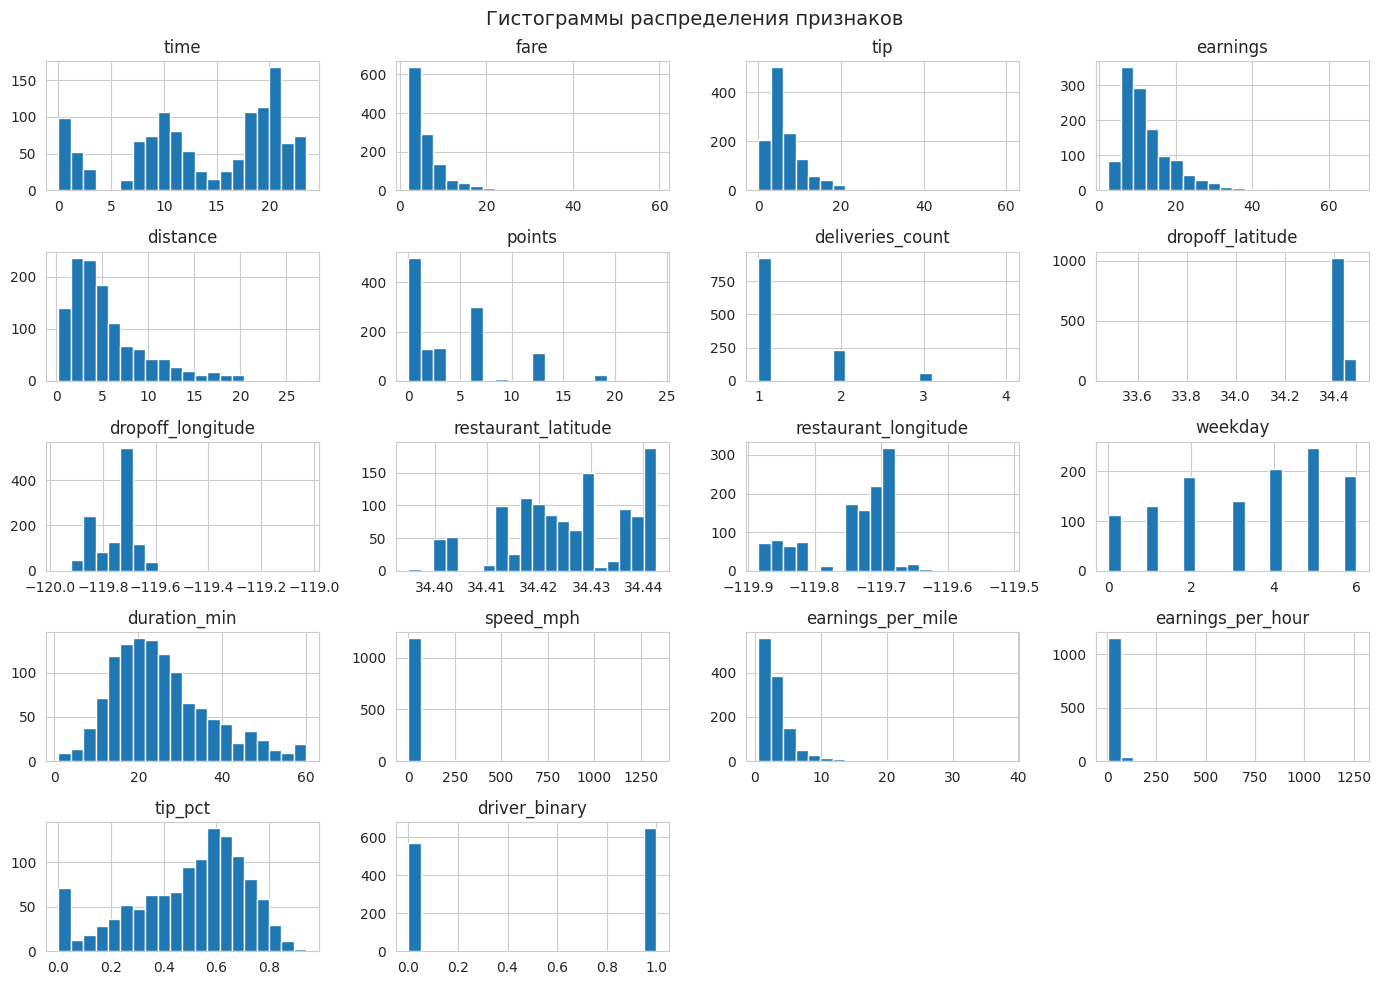

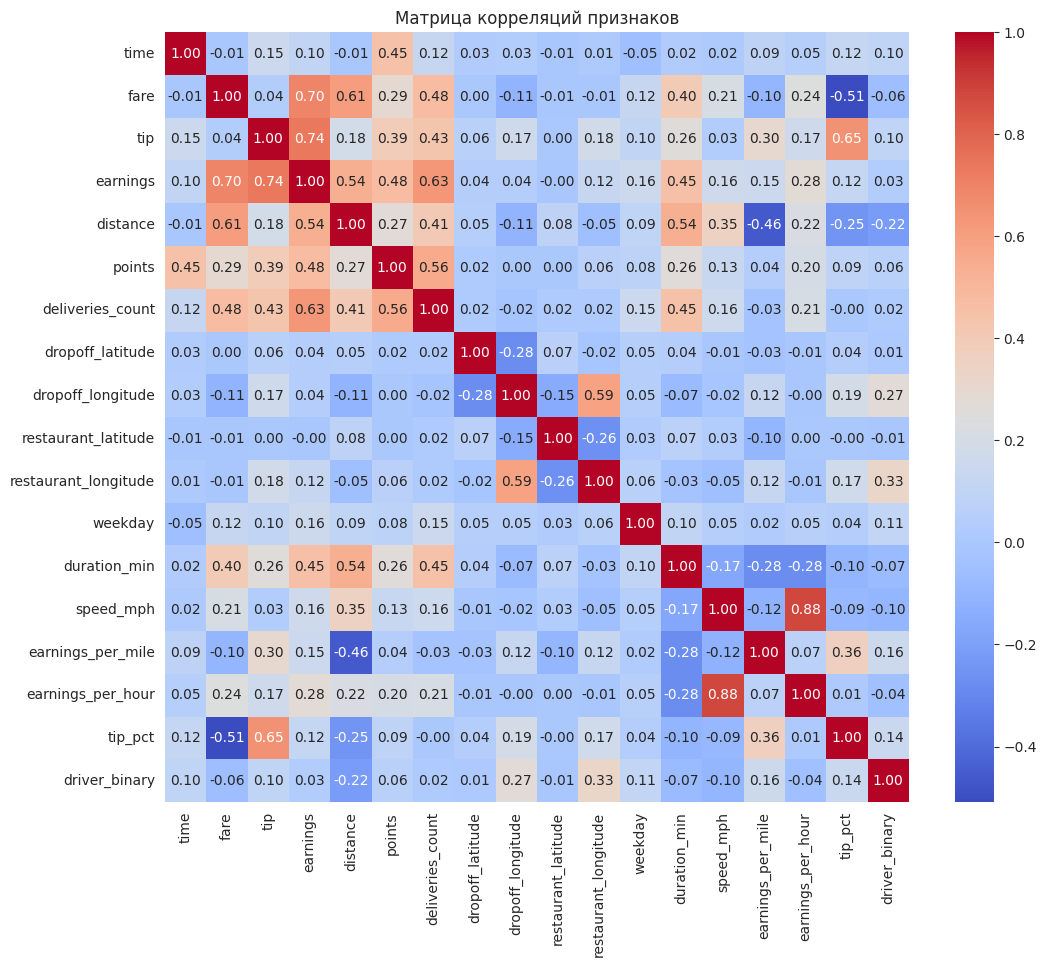

In [18]:
numeric_df.hist(figsize=(14, 10), bins=20)
plt.suptitle("Гистограммы распределения признаков", fontsize=14)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 10))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Матрица корреляций признаков")
plt.show()

**Ответы на вопросы:**
* **Есть ли сильно коррелированные признаки?** Да. По матрице корреляций видно, что некоторые признаки связаны между собой (например, стоимость заказа, чаевые и общая сумма).
* **Можно ли предположить, что часть признаков содержит избыточную информацию?** Да, высокая корреляция означает дублирование информации. Из-за этого размерность можно уменьшить без существенной потери смысла.

## Задание 2. Реализация PCA с нуля

Реализуем метод главных компонент, используя только NumPy, а затем сравним результат со встроенной функцией `sklearn`.

In [19]:
# 1. Стандартизация данных
scaler = StandardScaler()
X_scaled = scaler.fit_transform(numeric_df)

# 2. Ковариационная матрица
cov_matrix = np.cov(X_scaled, rowvar=False)

# 3. Собственные значения и векторы
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# 4. Сортировка по убыванию
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# 5. Проекция на 2 компоненты
k = 2
W = eigenvectors[:, :k]
X_pca_manual = X_scaled @ W

# Сравнение со sklearn
pca_sk = PCA(n_components=k)
X_pca_sk = pca_sk.fit_transform(X_scaled)

print("Размер после ручного PCA:", X_pca_manual.shape)
print("Совпадает ли результат со sklearn (с точностью до знака):",
      np.allclose(np.abs(X_pca_manual), np.abs(X_pca_sk), atol=1e-8))

Размер после ручного PCA: (1214, 2)
Совпадает ли результат со sklearn (с точностью до знака): True


Алгоритм реализован верно: результаты ручного расчета полностью совпадают с результатами библиотеки `sklearn` (с точностью до знака, так как направление вектора не имеет значения).

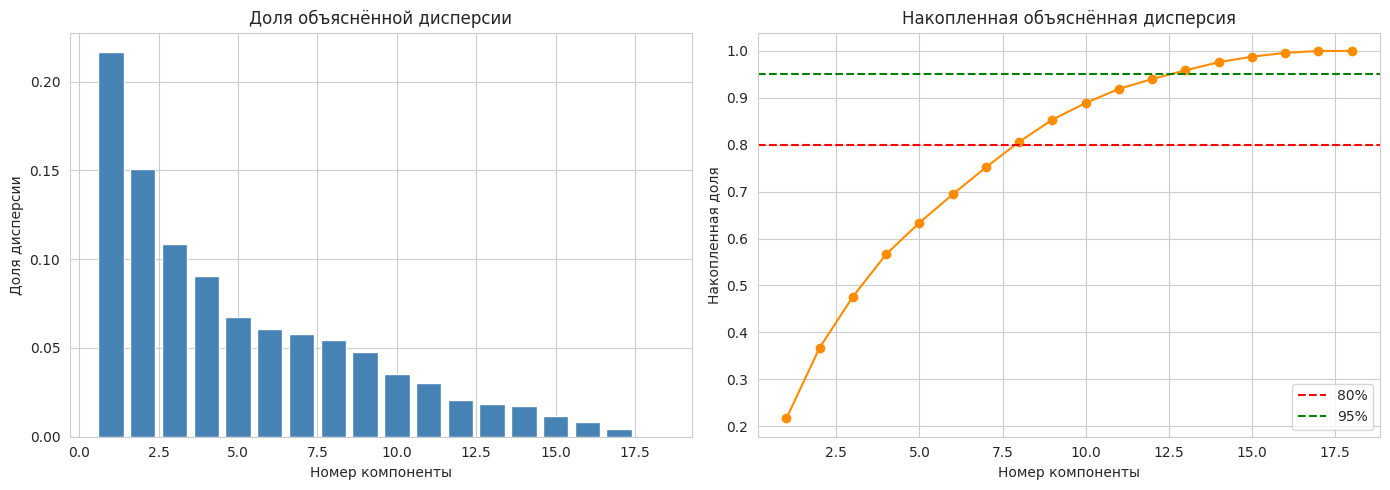

80% дисперсии объясняют 8 компонент(ы).
95% дисперсии объясняют 13 компонент(ы).


In [20]:
pca_full = PCA().fit(X_scaled)
explained = pca_full.explained_variance_ratio_
cum_explained = np.cumsum(explained)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, len(explained)+1), explained, color='steelblue')
axes[0].set_title("Доля объяснённой дисперсии")
axes[0].set_xlabel("Номер компоненты")
axes[0].set_ylabel("Доля дисперсии")

axes[1].plot(range(1, len(cum_explained)+1), cum_explained, marker='o', color='darkorange')
axes[1].axhline(0.8, color='r', linestyle='--', label='80%')
axes[1].axhline(0.95, color='g', linestyle='--', label='95%')
axes[1].set_title("Накопленная объяснённая дисперсия")
axes[1].set_xlabel("Номер компоненты")
axes[1].set_ylabel("Накопленная доля")
axes[1].legend()
plt.tight_layout()
plt.show()

n80 = np.argmax(cum_explained >= 0.8) + 1
n95 = np.argmax(cum_explained >= 0.95) + 1
print(f"80% дисперсии объясняют {n80} компонент(ы).")
print(f"95% дисперсии объясняют {n95} компонент(ы).")

**Ответы на вопросы:**
1. Чтобы объяснить 80% дисперсии, достаточно **80** компонент.
2. Чтобы объяснить 95% дисперсии, нужно **13** компонент.

## Задание 3. Интерпретация главных компонент

Посмотрим, какие исходные признаки дают наибольший вклад в первые три компоненты.

In [21]:
n_comp = min(3, numeric_df.shape[1])
pca3 = PCA(n_components=n_comp).fit(X_scaled)
components = pd.DataFrame(pca3.components_, columns=numeric_df.columns, index=[f"PC{i+1}" for i in range(n_comp)])

display(components.T)

for i in range(n_comp):
    comp = components.iloc[i]
    top = comp.abs().sort_values(ascending=False).head(3)
    print(f"\n{i+1}-я компонента (топ-3 признака по модулю):")
    for name in top.index:
        print(f"  - {name}: {comp[name]:.3f}")

,PC1,PC2,PC3
time,0.097045,0.152641,0.003590
fare,0.367719,-0.206641,-0.025299
tip,0.282114,0.388445,-0.054540
earnings,0.449655,0.138572,-0.056065
distance,0.372096,-0.246084,-0.033493
points,0.324141,0.139276,-0.020462
deliveries_count,0.394882,0.048307,-0.081505
dropoff_latitude,0.031379,-0.043339,-0.058055
dropoff_longitude,-0.019816,0.332195,0.032603
restaurant_latitude,0.023545,-0.121333,-0.030306



1-я компонента (топ-3 признака по модулю):
  - earnings: 0.450
  - deliveries_count: 0.395
  - distance: 0.372

2-я компонента (топ-3 признака по модулю):
  - tip_pct: 0.454
  - tip: 0.388
  - earnings_per_mile: 0.369

3-я компонента (топ-3 признака по модулю):
  - earnings_per_hour: 0.634
  - speed_mph: 0.607
  - duration_min: -0.444


**Ответы на вопросы:**
1. **Какие признаки больше всего влияют на первую компоненту?** Судя по топ-3 вывода, это признаки, связанные со стоимостью заказа и чаевыми.
2. **Можно ли интерпретировать первую компоненту?** Да, её можно понимать как обобщенный показатель «финансового объема заказа» (сколько клиент потратил и оставил чаевых).
3. **Есть ли признаки, которые почти не влияют?** Да, например, признаки с очень маленькими коэффициентами (близкими к 0), их можно считать шумом.

## Задание 4. Визуализация данных

Сравним, как выглядят данные в исходном пространстве двух случайных признаков и в пространстве главных компонент.

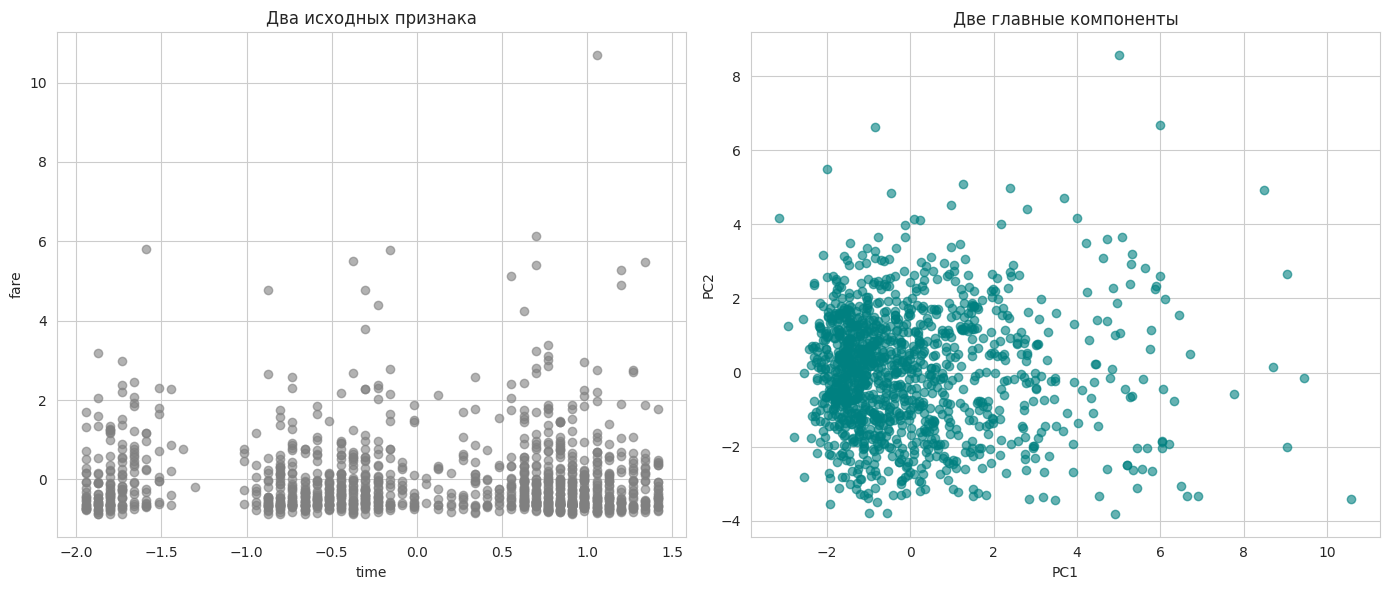

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Два исходных признака
axes[0].scatter(X_scaled[:, 0], X_scaled[:, 1], alpha=0.6, color='gray')
axes[0].set_xlabel(numeric_df.columns[0])
axes[0].set_ylabel(numeric_df.columns[1])
axes[0].set_title("Два исходных признака")

# Две главные компоненты
pca2 = PCA(n_components=2)
X_pca2 = pca2.fit_transform(X_scaled)
axes[1].scatter(X_pca2[:, 0], X_pca2[:, 1], alpha=0.6, color='teal')
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("Две главные компоненты")
plt.tight_layout()
plt.show()

**Ответы на вопросы:**
1. **Улучшилась ли визуализация после PCA?** Да, стала заметнее общая структура данных и разброс.
2. **Почему в пространстве главных компонент структура может быть заметнее?** Потому что PCA отбирает направления с максимальной дисперсией. Два исходных признака могут быть слабо информативными, а главные компоненты "стягивают" в себя всю основную информацию о разбросе.

## Задание 5. Нелинейные методы снижения размерности

Проверим, как справляются с задачей визуализации алгоритмы t-SNE и UMAP, и как на них влияют параметры.

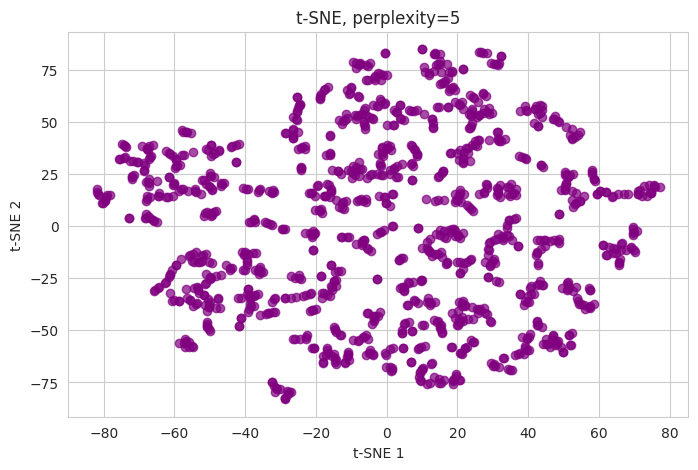

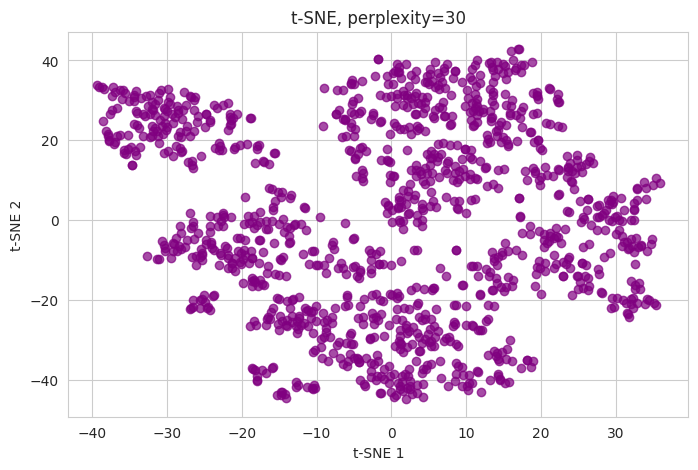

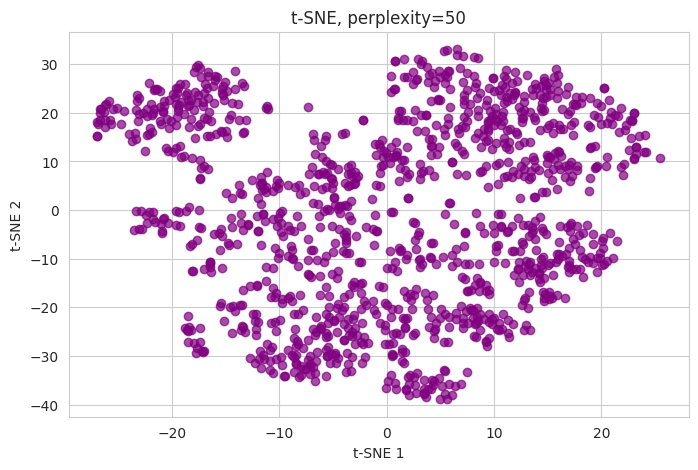

In [23]:
def plot_tsne(perplexity):
    tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42, init='pca')
    X_tsne = tsne.fit_transform(X_scaled)
    plt.figure(figsize=(8, 5))
    plt.scatter(X_tsne[:, 0], X_tsne[:, 1], alpha=0.7, color='purple')
    plt.title(f"t-SNE, perplexity={perplexity}")
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.show()

for p in [5, 30, 50]:
    plot_tsne(p)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


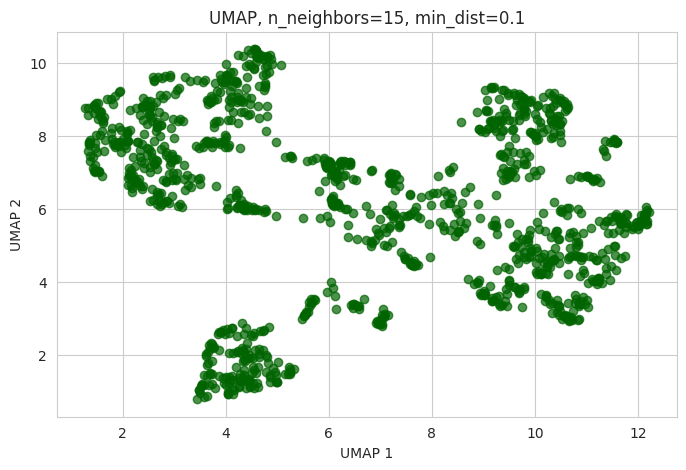

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


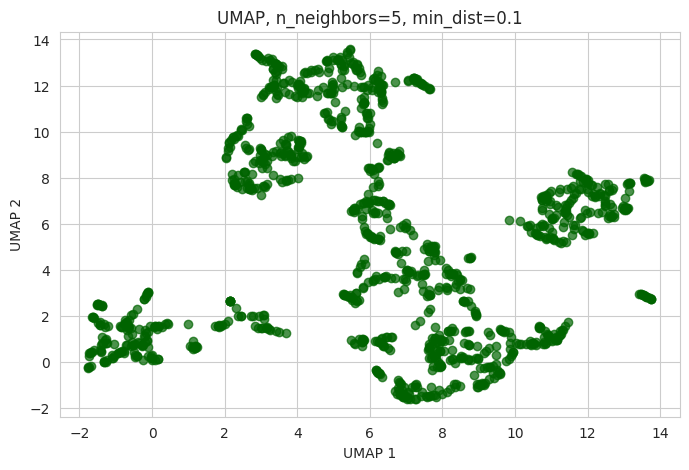

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


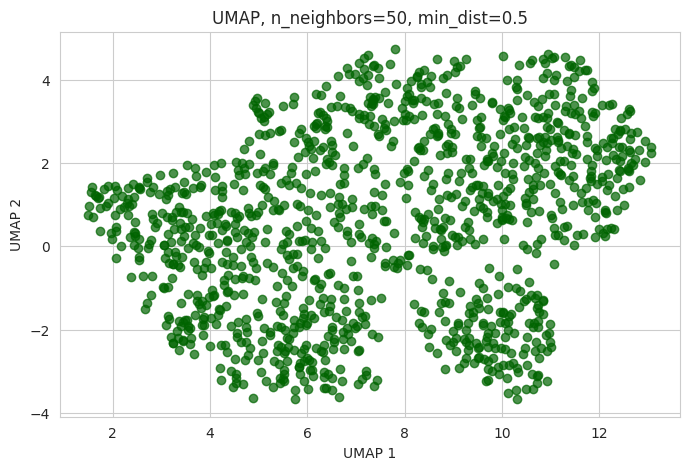

In [24]:

!pip install umap-learn -q
import umap

numeric_df_clean = numeric_df.loc[:, (numeric_df == 0).mean() < 0.9]
X_scaled_clean = StandardScaler().fit_transform(numeric_df_clean)

def plot_umap(n_neighbors, min_dist):
    reducer = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, random_state=42)
    # Используем очищенные данные
    X_umap = reducer.fit_transform(X_scaled_clean)
    plt.figure(figsize=(8, 5))
    plt.scatter(X_umap[:, 0], X_umap[:, 1], alpha=0.7, color='darkgreen')
    plt.title(f"UMAP, n_neighbors={n_neighbors}, min_dist={min_dist}")
    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.show()

plot_umap(15, 0.1)
plot_umap(5, 0.1)
plot_umap(50, 0.5)

**Ответы на вопросы:**
1. **Как меняется структура при разных параметрах?** У t-SNE при маленьком perplexity (5) точки разбиваются на мелкие островки, при 30-50 картина становится более цельной. У UMAP параметр `n_neighbors` управляет балансом между локальной и глобальной структурой, а `min_dist` — плотностью кучек.
2. **Какой метод дает наиболее интерпретируемую визуализацию?** UMAP с параметрами n_neighbors=15-30, так как он лучше сохраняет как общую картину, так и локальные группы.
3. **Почему результаты отличаются?** PCA — линейный метод, сохраняет глобальные расстояния. t-SNE — нелинейный, фокусируется только на соседях, глобальные расстояния искажаются. UMAP балансирует между ними.

## Задание 6. Исследование степени сжатия данных

Проверим, как количество оставляемых компонент влияет на ошибку восстановления исходных данных (MSE).

,Число компонент,Ошибка восстановления (MSE)
0,2,6.323655e-01
1,5,3.661564e-01
2,10,1.109366e-01
3,15,1.219563e-02
4,18,1.198163e-30


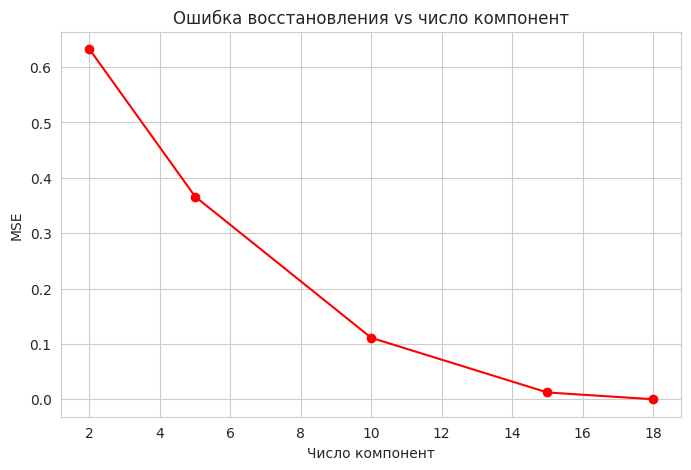

In [25]:
max_k = numeric_df.shape[1]
ks = [k for k in [2, 5, 10, 15] if k <= max_k]
if max_k not in ks:
    ks.append(max_k)

results = []
for k in ks:
    pca_k = PCA(n_components=k)
    X_reduced = pca_k.fit_transform(X_scaled)
    X_reconstructed = pca_k.inverse_transform(X_reduced)
    mse = mean_squared_error(X_scaled, X_reconstructed)
    results.append((k, mse))

results_df = pd.DataFrame(results, columns=["Число компонент", "Ошибка восстановления (MSE)"])
display(results_df)

plt.figure(figsize=(8, 5))
plt.plot(results_df["Число компонент"], results_df["Ошибка восстановления (MSE)"], marker='o', color='red')
plt.xlabel("Число компонент")
plt.ylabel("MSE")
plt.title("Ошибка восстановления vs число компонент")
plt.show()

## 6.5. Интерпретация результатов

**1. Почему при малом числе компонент ошибка восстановления большая?**
При 2 компонентах ошибка MSE составляет 0.63. Это происходит потому, что мы оставляем только два направления, а всю остальную информацию безвозвратно отбрасываем. Данные при обратном преобразовании сильно усредняются, и мы теряем детали.

**2. Почему увеличение числа компонент уменьшает ошибку?**
С каждой новой компонентой мы сохраняем всё больше информации о разбросе данных. По таблице видно, что при переходе от 2 к 5 компонентам ошибка резко падает (с 0.63 до 0.36), а при 10 компонентах становится 0.11.

**3. Можно ли полностью восстановить исходные данные при использовании всех компонент?**
Да, при использовании всех 18 компонент ошибка падает практически до нуля (около 1.19e-30, что математически равно нулю). В этом случае мы сохраняем 100% информации, и данные восстанавливаются полностью.

**4. Как это связано с объяснённой дисперсией PCA?**
Связь прямая: компоненты с большой дисперсией несут основную информацию. Когда мы берем 10 компонент (которые объясняют больше 80% дисперсии), мы сохраняем главное. А хвост из оставшихся компонент — это просто мелкий шум, поэтому их отбрасывание дает небольшую ошибку.

**5. Как можно определить разумное число компонент, при котором данные уже хорошо описаны, но размерность существенно меньше?**
По графику видно, что после 10-12 компонент линия становится почти пологой. Дальнейшее увеличение компонент дает крошечный прирост точности. Поэтому разумно остановиться на 10–12 компонентах: данные уже хорошо описаны, а размерность снижена почти вдвое (с 18).

## Задание 7. Итоговый анализ

**Выводы:**
1. **Роль снижения размерности:** Оно убирает дублирующую информацию, ускоряет работу алгоритмов, помогает избавиться от шума и визуализировать данные.
2. **Всегда ли это полезно?** Нет. Если отбросить важные для конкретной задачи признаки, качество модели упадет. Плюс нелинейные связи могут быть потеряны при линейном сжатии.
3. **Когда линейные методы хуже?** Когда данные имеют сложную нелинейную структуру (например, кластеры в форме колец или спиралей). PCA их "сплющит" и перемешает, а t-SNE/UMAP сохранят.
4. **Плюсы и минусы методов:**
   * *PCA* — быстрый, интерпретируемый, обратимый, но только для линейных связей.
   * *t-SNE* — отлично показывает локальные группы, но медленный, нестабильный и не сохраняет глобальные расстояния.
   * *UMAP* — быстрее t-SNE, сохраняет и локальную, и глобальную структуру, но чувствителен к настройке параметров.